# Notebook 07：等权合成、滚动 IC 与 ICIR 加权

本节把 EP、ROE、12-1 动量和 60 日低波动合成为股票综合评分，回答：

> 不同类别的因子能否互相补充？根据历史预测能力调整权重，能否稳定超过简单等权？

固定使用 Notebook 06 的 **行业 + 市值中性化、残差 Z-score** 版本。每类选一个因子，
避免价值、质量因子因数量更多而被隐式超配；不根据本次结果调整因子或窗口。
核心函数位于 `src/multifactor/`，本 Notebook 负责研究参数、调用、展示与保存结果。

## 1. 方法与时间约定

**方法 A：等权基准**：$Score^{EW}_{i,t}=\frac14\sum_{k=1}^{4}z_{i,k,t}$。

**方法 B：滚动 IC 加权**：使用截至信号日已实现收益的最近 36 个正式月份，计算各因子平均 Rank IC：

$$w^{IC}_{k,t}=\frac{\overline{IC}_{k,t}^{hist}}{\sum_j|\overline{IC}_{j,t}^{hist}|},
\qquad Score^{IC}_{i,t}=\sum_k w^{IC}_{k,t}z_{i,k,t}.$$

**方法 C：滚动 ICIR 加权**：在完全相同的历史窗口内，同时计算 IC 均值和样本标准差：

$$ICIR^{hist}_{k,t}=\frac{\overline{IC}_{k,t}^{hist}}{s(IC^{hist}_{k,t})},
\quad w^{ICIR}_{k,t}=\frac{ICIR^{hist}_{k,t}}{\sum_j|ICIR^{hist}_{j,t}|},
\quad Score^{ICIR}_{i,t}=\sum_k w^{ICIR}_{k,t}z_{i,k,t}.$$

ICIR 加权同时考虑预测强度和稳定性。例如两个因子平均 IC 相同，但第二个的历史 IC 标准差
更大，它得到的绝对权重就更小。标准差使用 `ddof=1`，ICIR 不年化；若各因子统一乘以
$\sqrt{12}$ 年化，该公共倍数也会在权重归一化时抵消。

- 两种滚动方法均固定使用 36 个月窗口，且每个因子都要求 36 个有效 IC；不足时信号留空，不回退为其他方法。
- IC 按**因子信号日**标记，其可用日是标签对应的下一正式调仓日。例如 1 月信号的 IC 到 2 月收盘后才能知道；2 月收盘形成新信号时可使用它。ICIR 的均值与标准差均遵守此时间边界。
- 允许负权重，表示反向使用历史平均 IC 为负的因子；每月权重绝对值之和为 1，不做正权重截断或平滑。
- ICIR 至少需要两个有效月份来估计样本标准差。任一因子的 IC 标准差为零或无法估计时，当月整组 ICIR 权重留空；不事后删除该因子。
- 完全常数的 IC 序列按零标准差处理，避免浮点舍入误差生成极高 ICIR。对真实变化但很小的正标准差不设额外阈值；由此产生的权重集中通过图表和窗口审计观察。
- 每只股票必须当期合格且四个因子全部有效；任一缺失就不评分。相同完整样本也用于估计各因子历史 IC。
- 先按当期评分建立五分位等权持仓，再连接未来收益。没有未来标签不会影响评分或持仓。
- 这里的标签沿用 close-to-close 研究口径；最终可成交的组合、费用和约束留给 08/09。

In [1]:
%matplotlib inline

from pathlib import Path
import sys

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'data' / 'processed').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.factors import calculate_monthly_rank_ic, summarize_rank_ic
from src.portfolio import (
    annualized_return, build_factor_return_panel,
    calculate_cumulative_returns, calculate_return_metrics,
)
from src.multifactor import (
    combine_factor_scores, calculate_rolling_ic_weights, calculate_rolling_icir_weights,
    build_quantile_holdings, calculate_holdings_returns, calculate_target_turnover,
)

PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
FIGURES_DIR = PROJECT_ROOT / 'figures'
REPORTS_DIR = PROJECT_ROOT / 'reports'
FIGURES_DIR.mkdir(exist_ok=True)
REPORTS_DIR.mkdir(exist_ok=True)
INPUT_PATH = PROCESSED_DIR / 'factor_panel_industry_size_neutral.parquet'
FACTOR_LABELS = {
    'ep': 'EP', 'roe': 'ROE',
    'momentum_12_1': 'MOM 12-1', 'low_volatility_60d': 'LOWVOL 60D',
}
FACTOR_COLUMNS = list(FACTOR_LABELS)
WINDOW = 36
MIN_HISTORY = 36
MIN_OBSERVATIONS = 30
N_QUANTILES = 5
PERIODS_PER_YEAR = 12
SCORE_COLUMNS = ['best_single_score', 'equal_weight_score', 'ic_weight_score', 'icir_weight_score']
METHOD_LABELS = {
    'best_single_score': 'Training-selected single',
    'equal_weight_score': 'Equal weight',
    'ic_weight_score': 'Rolling IC weight',
    'icir_weight_score': 'Rolling ICIR weight',
}
# 保留原三种方法的颜色；ICIR 使用紫色，便于与等权的橙色区分。
method_palette = sns.color_palette('colorblind', 5)
COLORS = dict(zip(SCORE_COLUMNS, [method_palette[i] for i in (0, 1, 2, 4)]))
sns.set_theme(style='whitegrid', context='notebook')
print(f'解释器：{sys.executable}')
print(f'输入：{INPUT_PATH.name}；历史窗口：{WINDOW} 个月')

解释器：/Users/mac/Desktop/a-share-multifactor/.venv/bin/python
输入：factor_panel_industry_size_neutral.parquet；历史窗口：36 个月


## 2. 输入、完整因子样本与标签时间轴

这里读取上游已经生成的联合中性化面板，不重复运行数据下载和因子构造。
保留完整股票—月份骨架，并另记 `has_complete_factors`；收益标签资格仅用于事后评估。

当前因子面板没有保留 `label_end_date`，因此严格按 Notebook 02 的定义，
从**全体正式调仓日**建立“当前月 → 下一月”映射。不能按某只股票的下一条记录映射。
最后一月没有终点，其 IC 可用日记为 `NaT`，但它仍然可以有预测评分。

In [2]:
context_columns = [
    'date', 'stock_code', 'industry', 'size', 'is_eligible',
    'future_return_1m', 'is_in_label_sample', 'label_available', 'label_status',
]
panel = pd.read_parquet(INPUT_PATH, columns=context_columns + FACTOR_COLUMNS)
panel['date'] = pd.to_datetime(panel['date'])
signal_dates = pd.DatetimeIndex(sorted(panel['date'].unique()), name='date')
# 研究时点检查：上游月度日历完整，且每只股票每个时点只有一条记录。
assert not panel.duplicated(['date', 'stock_code']).any()
assert signal_dates.to_period('M').equals(
    pd.period_range(signal_dates[0], signal_dates[-1], freq='M')
)
# ic_available_dates 是一个以日期为索引的 Series,
# 每个 index 对应下一个调仓日
ic_available_dates = pd.Series(signal_dates, index=signal_dates).shift(-1)
ic_available_dates.name = 'ic_available_date'
# label_end_date 是每条股票记录对应的下一个调仓日
panel['label_end_date'] = panel['date'].map(ic_available_dates)

complete_mask = panel['is_eligible'].fillna(False) & panel[FACTOR_COLUMNS].notna().all(axis=1)
panel['has_complete_factors'] = complete_mask
# 所有因子历史 IC 使用同一完整样本，不能让某个因子因可用股票更多而获益。
label_mask = complete_mask & panel['is_in_label_sample'].fillna(False)
# coverage 是一张按月份统计样本数量和数据覆盖情况的表，
# 每行对应一个调仓日，表示当月有多少股票、多少因子齐全的股票等
coverage = panel.groupby('date', observed=True).agg(
    total_stocks=('stock_code', 'size'),
    eligible_stocks=('is_eligible', 'sum'),
    complete_factor_stocks=('has_complete_factors', 'sum'),
)
coverage['observable_label_stocks'] = panel.loc[label_mask].groupby('date', observed=True).size()
coverage['observable_label_stocks'] = coverage['observable_label_stocks'].fillna(0).astype(int)
coverage['factor_coverage'] = coverage['complete_factor_stocks'] / coverage['eligible_stocks']
coverage.to_csv(PROCESSED_DIR / 'multifactor_sample_coverage.csv')
print(f'输入：{len(panel):,} 行，{len(signal_dates)} 个信号月')
print(f'完整四因子样本起点：{panel.loc[complete_mask, "date"].min():%Y-%m-%d}')
display(coverage.iloc[[0, 9, -2, -1]])

输入：426,474 行，96 个信号月
完整四因子样本起点：2018-10-31


,total_stocks,eligible_stocks,complete_factor_stocks,observable_label_stocks,factor_coverage
date,,,,,
2018-01-31,3482,2967,0,0,0.000000
2018-10-31,3556,3253,2740,2734,0.842299
2025-11-28,5169,4926,4796,4787,0.973609
2025-12-31,5183,4934,4791,0,0.971017


## 3. 历史 Rank IC、两种滚动权重与可用日审计

单因子 IC 用于估计两种历史权重。每月股票截面至少 30 个有效样本，
ICIR 延续 Notebook 04/06 的非年化定义 `Mean(IC) / Std(IC)`。

先计算整张历史 IC 表，再由两个函数共用的时间筛选逻辑，按每个 IC 的可用日期截取历史。
IC 加权仅使用窗口内均值；ICIR 加权在同一窗口内再估计 IC 标准差，不使用全样本波动率。

两个审计表均记录实际使用的历史起止日期、最近收益实现日、窗口大小和最少有效 IC 数量。
ICIR 审计表另外记录 `min_ic_std` 和 `has_valid_ic_std`，分别表示窗口内各因子 IC 标准差的
最小值，以及所有因子的标准差是否都有效且大于零。

In [3]:
monthly_factor_ic = calculate_monthly_rank_ic(
    panel.loc[label_mask], FACTOR_COLUMNS, min_observations=MIN_OBSERVATIONS,
).reindex(signal_dates)
rolling_weights, weight_audit = calculate_rolling_ic_weights(
    monthly_factor_ic, ic_available_dates, signal_dates,
    window=WINDOW, min_history=MIN_HISTORY,
)
rolling_icir_weights, icir_weight_audit = calculate_rolling_icir_weights(
    monthly_factor_ic, ic_available_dates, signal_dates,
    window=WINDOW, min_history=MIN_HISTORY,
)
ready_dates = rolling_weights.dropna().index
icir_ready_dates = rolling_icir_weights.dropna().index
# 单因子仍在原 IC 加权首次就绪时选定，新增方法不会重选基准或调整历史窗口。
first_ready_date = ready_dates.min()
first_icir_ready_date = icir_ready_dates.min()
rolling_methods = {
    'ic_weight_score': (rolling_weights, weight_audit),
    'icir_weight_score': (rolling_icir_weights, icir_weight_audit),
}

# 等权可从完整因子样本出现时生成；两种滚动评分必须等待各自历史估计量可用。
panel['equal_weight_score'] = combine_factor_scores(panel, FACTOR_COLUMNS)
for score, (weights, audit) in rolling_methods.items():
    panel[score] = combine_factor_scores(panel, FACTOR_COLUMNS, weights, score_name=score)
    method_ready_dates = weights.dropna().index
    assert np.allclose(weights.loc[method_ready_dates].abs().sum(axis=1), 1.0)
    assert audit.loc[method_ready_dates, 'history_end'].lt(method_ready_dates).all()
    assert audit.loc[method_ready_dates, 'latest_available_date'].le(method_ready_dates).all()
    assert audit.loc[method_ready_dates, 'min_valid_ic_months'].ge(MIN_HISTORY).all()
assert icir_weight_audit.loc[icir_ready_dates, 'has_valid_ic_std'].all()
assert panel.loc[~complete_mask, ['equal_weight_score', *rolling_methods]].isna().all().all()

monthly_factor_ic.to_parquet(PROCESSED_DIR / 'multifactor_factor_rank_ic_monthly.parquet')
rolling_weights.to_csv(PROCESSED_DIR / 'multifactor_rolling_ic_weights.csv')
weight_audit.join(ic_available_dates).to_csv(PROCESSED_DIR / 'multifactor_weight_history_audit.csv')
rolling_icir_weights.to_csv(PROCESSED_DIR / 'multifactor_rolling_icir_weights.csv')
icir_weight_audit.join(ic_available_dates).to_csv(PROCESSED_DIR / 'multifactor_icir_weight_history_audit.csv')
print(f'首个滚动 IC 信号月：{first_ready_date:%Y-%m-%d}')
print(f'首个滚动 ICIR 信号月：{first_icir_ready_date:%Y-%m-%d}')
for score, (weights, audit) in rolling_methods.items():
    display(Markdown(f'**{METHOD_LABELS[score]}：历史窗口审计和首批权重**'))
    display(audit.loc[audit.is_ready].head())
    display(weights.dropna().rename(columns=FACTOR_LABELS).head().style.format('{:+.2%}'))

首个滚动 IC 信号月：2021-10-29
首个滚动 ICIR 信号月：2021-10-29


**Rolling IC weight：历史窗口审计和首批权重**

,history_start,history_end,latest_available_date,n_periods,min_valid_ic_months,is_ready
date,,,,,,
2021-10-29,2018-10-31,2021-09-30,2021-10-29,36,36,True
2021-11-30,2018-11-30,2021-10-29,2021-11-30,36,36,True
2021-12-31,2018-12-28,2021-11-30,2021-12-31,36,36,True
2022-01-28,2019-01-31,2021-12-31,2022-01-28,36,36,True
2022-02-28,2019-02-28,2022-01-28,2022-02-28,36,36,True


,EP,ROE,MOM 12-1,LOWVOL 60D
date,,,,
2021-10-29 00:00:00,+19.98%,+18.26%,+1.94%,+59.82%
2021-11-30 00:00:00,+19.94%,+20.58%,+4.31%,+55.17%
2021-12-31 00:00:00,+21.40%,+17.94%,-0.87%,+59.78%
2022-01-28 00:00:00,+20.79%,+16.12%,-5.93%,+57.15%
2022-02-28 00:00:00,+21.28%,+17.35%,+3.27%,+58.09%


**Rolling ICIR weight：历史窗口审计和首批权重**

,history_start,history_end,latest_available_date,n_periods,min_valid_ic_months,is_ready,min_ic_std,has_valid_ic_std
date,,,,,,,,
2021-10-29,2018-10-31,2021-09-30,2021-10-29,36,36,True,0.073604,True
2021-11-30,2018-11-30,2021-10-29,2021-11-30,36,36,True,0.073502,True
2021-12-31,2018-12-28,2021-11-30,2021-12-31,36,36,True,0.072470,True
2022-01-28,2019-01-31,2021-12-31,2022-01-28,36,36,True,0.072354,True
2022-02-28,2019-02-28,2022-01-28,2022-02-28,36,36,True,0.067659,True


,EP,ROE,MOM 12-1,LOWVOL 60D
date,,,,
2021-10-29 00:00:00,+26.04%,+24.53%,+1.91%,+47.52%
2021-11-30 00:00:00,+25.74%,+27.40%,+4.28%,+42.58%
2021-12-31 00:00:00,+28.00%,+24.90%,-0.90%,+46.20%
2022-01-28 00:00:00,+27.06%,+23.06%,-6.14%,+43.75%
2022-02-28 00:00:00,+26.23%,+24.06%,+3.46%,+46.25%


## 4. 在初始历史窗口选定单因子基准

“最佳单因子”不能从完整比较期事后选取。本节只使用首次 IC 权重可用时的同一历史窗口，
按平均 Rank IC 选择一个单因子，之后固定不变；不反向调方向，不每月重新选冠军。

三种合成方法及该单因子均使用完整四因子股票样本。后续比较使用所有方法均有效的共同月份，
避免等权因多包含早期年份而获得不公平的表现差异。

这属于**初始历史选基准 + 向前滚动估计权重**的研究比较。此前 04–06 已展示全样本诊断，
本次也没有隔离最终测试集，因此不能把这里称为未触碰的独立样本外检验。

In [4]:
training_known = ic_available_dates.notna() & ic_available_dates.le(first_ready_date)
training_ic = monthly_factor_ic.loc[training_known].tail(WINDOW)
training_summary = summarize_rank_ic(training_ic)
best_factor = training_summary['Mean Rank IC'].idxmax()
panel['best_single_score'] = panel[best_factor].where(complete_mask)
training_summary['selected'] = training_summary.index == best_factor
training_summary.to_csv(PROCESSED_DIR / 'multifactor_initial_training_summary.csv')
print(f'基准选择窗口：{training_ic.index.min():%Y-%m-%d} 至 {training_ic.index.max():%Y-%m-%d}')
print(f'窗口最后的收益实现日：{ic_available_dates.loc[training_ic.index].max():%Y-%m-%d}')
print(f'固定单因子基准：{FACTOR_LABELS[best_factor]}（只按初始历史 Mean Rank IC 选择）')
display(training_summary.rename(index=FACTOR_LABELS).style.format({
    'Mean Rank IC': '{:.4f}', 'ICIR': '{:.3f}', 'Positive IC %': '{:.1%}',
}))

基准选择窗口：2018-10-31 至 2021-09-30
窗口最后的收益实现日：2021-10-29
固定单因子基准：LOWVOL 60D（只按初始历史 Mean Rank IC 选择）


,Mean Rank IC,IC Std,ICIR,Positive IC %,IC t-stat,Months,selected
Factor,,,,,,,
EP,0.0241,0.075867,0.318,69.4%,1.906354,36,False
ROE,0.0220,0.073604,0.299,58.3%,1.795869,36,False
MOM 12-1,0.0023,0.100264,0.023,66.7%,0.140070,36,False
LOWVOL 60D,0.0722,0.124462,0.580,75.0%,3.479267,36,True


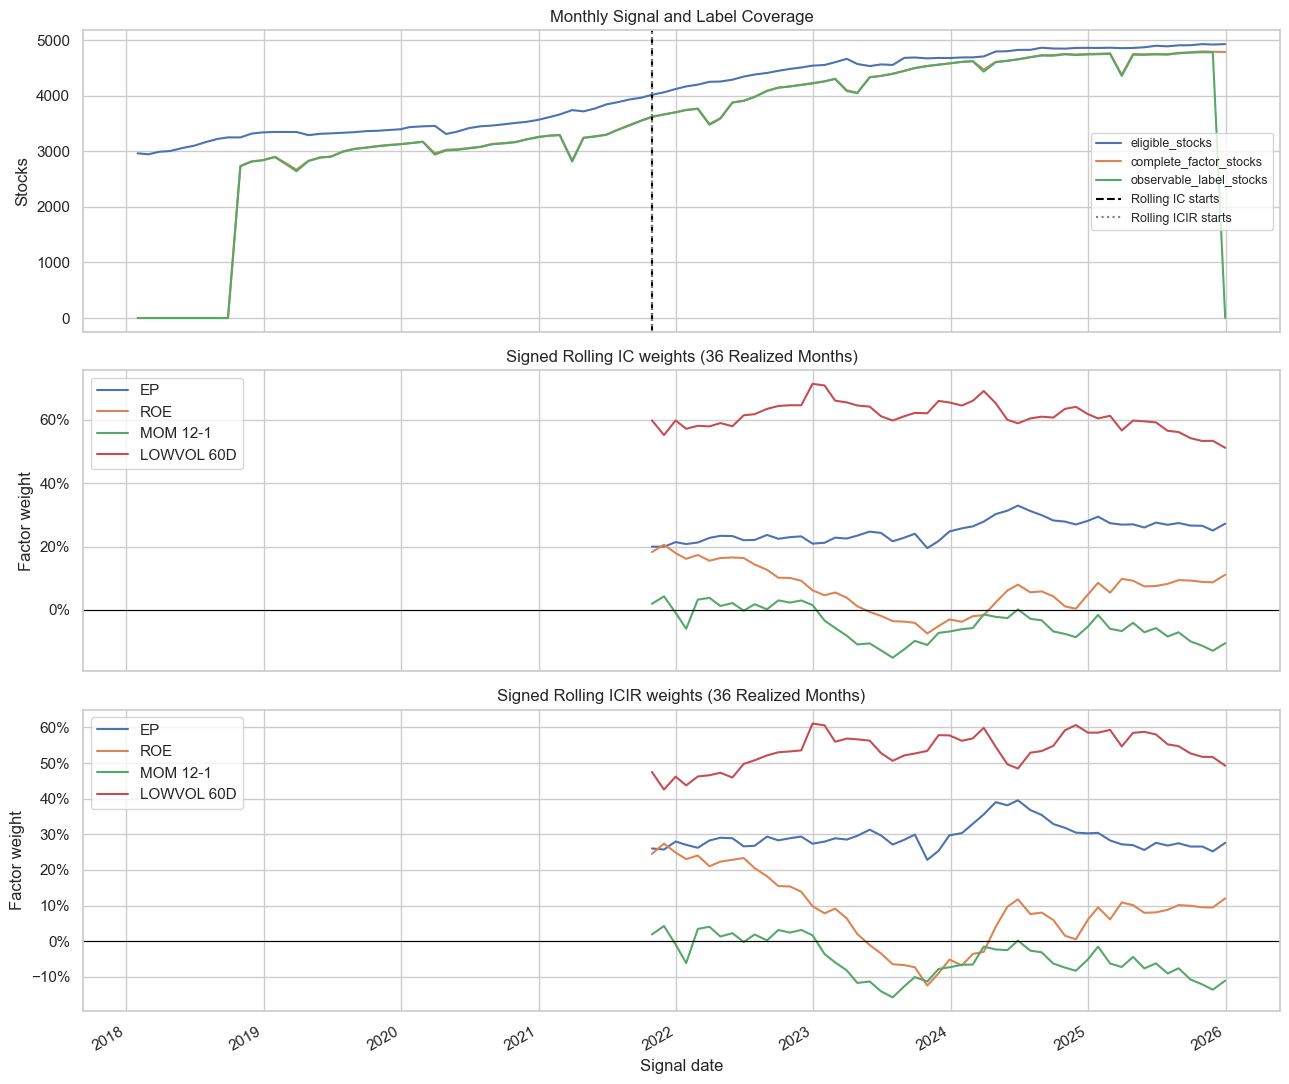

In [5]:
# 同一张图依次展示股票覆盖、IC 权重和 ICIR 权重，便于观察稳定性缩放的影响。
fig, axes = plt.subplots(3, 1, figsize=(13, 11), sharex=True)
coverage[['eligible_stocks', 'complete_factor_stocks', 'observable_label_stocks']].plot(ax=axes[0])
axes[0].axvline(first_ready_date, color='black', linestyle='--', label='Rolling IC starts')
axes[0].axvline(first_icir_ready_date, color='gray', linestyle=':', label='Rolling ICIR starts')
axes[0].set_title('Monthly Signal and Label Coverage')
axes[0].set_ylabel('Stocks')
axes[0].legend(fontsize=9)
for ax, (score, (weights, _)) in zip(axes[1:], rolling_methods.items()):
    weights.rename(columns=FACTOR_LABELS).plot(ax=ax, linewidth=1.5)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_title(f'Signed {METHOD_LABELS[score]}s ({WINDOW} Realized Months)')
    ax.set_ylabel('Factor weight')
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
axes[-1].set_xlabel('Signal date')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'multifactor_coverage_and_weights.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. 先生成持仓，再评价未来收益

四种评分在所有共同有效信号月中使用相同股票样本。先形成五分位组内等权目标持仓，
然后连接标签。事后标签缺失的股票仍占据原来的分组位置，不把其他股票补进来。

**收益解释边界**：缺少有效标签的持仓既不填零，也不补价格；各组仅在有效标签持仓内
重新归一化，计算可观察持仓条件平均收益，并保留 `label_coverage`。
因此本节的 Q5 收益和 Q5−Q1 收益用于预测诊断，尚不是完整可成交策略收益。

**换手率**：使用完整最高组目标持仓计算 `0.5 × Σ|w_t − w_(t−1)|`；
首个建仓月不计，缺月不跨越。它不依赖未来标签，尚未考虑持有期间的价格漂移。

In [6]:
# 用三个合成方法与单因子基准的共同信号样本建立持仓，保留最后一个无标签月份。
common_signal = panel[SCORE_COLUMNS].notna().all(axis=1)
signal_sample = panel.loc[common_signal]
holdings = build_quantile_holdings(
    signal_sample, SCORE_COLUMNS, n_quantiles=N_QUANTILES,
    min_observations=MIN_OBSERVATIONS,
)
quantile_returns = calculate_holdings_returns(holdings, panel)
turnover = calculate_target_turnover(holdings, signal_dates, quantile_number=N_QUANTILES)

# Rank IC 是横截面标签诊断，必须使用相同、可观察的股票样本。
common_label = common_signal & panel['is_in_label_sample'].fillna(False)
monthly_score_ic = calculate_monthly_rank_ic(
    panel.loc[common_label], SCORE_COLUMNS, min_observations=MIN_OBSERVATIONS,
).reindex(signal_dates)

# 指标只比较四种方法均有 IC、且所有五分位组均有可观察收益的共同月份。
returns_wide = quantile_returns.pivot(
    index='date', columns=['factor', 'quantile'], values='portfolio_return',
)
common_dates = monthly_score_ic.dropna().index.intersection(returns_wide.dropna().index)
evaluation_ic = monthly_score_ic.loc[common_dates, SCORE_COLUMNS]
evaluation_quantiles = quantile_returns.loc[quantile_returns['date'].isin(common_dates)]
evaluation_turnover = turnover.loc[turnover['date'].isin(common_dates)]

# 同一月份，同一分位组，四种方法的目标股票数应相同。
group_sizes = holdings.groupby(['date', 'factor', 'quantile_number'], observed=True).size()
assert group_sizes.unstack('factor').nunique(axis=1).eq(1).all()
assert holdings.groupby(['date', 'factor', 'quantile_number'], observed=True).weight.sum().between(1-1e-10, 1+1e-10).all()
assert not common_dates.empty
for score in rolling_methods:
    assert panel.loc[panel.date.eq(signal_dates[-1]), score].notna().any()
print(f'共同评价月份：{common_dates.min():%Y-%m-%d} 至 {common_dates.max():%Y-%m-%d}，共 {len(common_dates)} 个月')
print(f'最后信号月 {signal_dates[-1]:%Y-%m-%d} 保留评分及持仓，因没有下一期标签而不计收益。')

共同评价月份：2021-10-29 至 2025-11-28，共 50 个月
最后信号月 2025-12-31 保留评分及持仓，因没有下一期标签而不计收益。


## 6. 核心结果表

Q5 年化收益按可观察的月度组收益复利年化；多空 Sharpe 使用月收益均值 / 样本标准差 × √12，
无风险利率取零；Rank IC 的 ICIR 不年化。换手率是 Q5 的目标权重换手率。
最低标签覆盖率同时列出，避免把有条件的标签样本收益误当作完整账户收益。

In [7]:
ic_summary = summarize_rank_ic(evaluation_ic)
summary_rows = []
long_short_returns = pd.DataFrame(index=common_dates)
top_returns = pd.DataFrame(index=common_dates)
for score in SCORE_COLUMNS:
    return_panel = build_factor_return_panel(evaluation_quantiles, score, n_quantiles=N_QUANTILES)
    long_short_returns[score] = return_panel['Long-Short'].reindex(common_dates)
    top_returns[score] = return_panel['Q5'].reindex(common_dates)
    ls_metrics = calculate_return_metrics(long_short_returns[score], periods_per_year=PERIODS_PER_YEAR)
    top_coverage = evaluation_quantiles.loc[
        evaluation_quantiles.factor.eq(score) & evaluation_quantiles.quantile_number.eq(N_QUANTILES),
        'label_coverage',
    ]
    summary_rows.append({
        'Method': score,
        'Mean Rank IC': ic_summary.loc[score, 'Mean Rank IC'],
        'ICIR': ic_summary.loc[score, 'ICIR'],
        'Positive IC %': ic_summary.loc[score, 'Positive IC %'],
        'Q5 Annualized Return': annualized_return(top_returns[score]),
        'LS Annualized Return': ls_metrics['Annualized Return'],
        'LS Sharpe': ls_metrics['Sharpe Ratio'],
        'LS Max Drawdown': ls_metrics['Maximum Drawdown'],
        'Mean Target Turnover': evaluation_turnover.loc[evaluation_turnover.factor.eq(score), 'target_turnover'].mean(),
        'Mean Q5 Label Coverage': top_coverage.mean(),
        'Min Q5 Label Coverage': top_coverage.min(),
        'Months': len(common_dates),
        'Turnover Months': int(evaluation_turnover.loc[evaluation_turnover.factor.eq(score), 'target_turnover'].count()),
    })
comparison = pd.DataFrame(summary_rows).set_index('Method')
comparison.to_csv(PROCESSED_DIR / 'multifactor_comparison.csv')
percent_columns = ['Positive IC %', 'Q5 Annualized Return', 'LS Annualized Return',
                   'LS Max Drawdown', 'Mean Target Turnover',
                   'Mean Q5 Label Coverage', 'Min Q5 Label Coverage']
display(comparison.rename(index=METHOD_LABELS).style.format({
    **{column: '{:.2%}' for column in percent_columns},
    'Mean Rank IC': '{:.4f}', 'ICIR': '{:.3f}', 'LS Sharpe': '{:.2f}',
}))

,Mean Rank IC,ICIR,Positive IC %,Q5 Annualized Return,LS Annualized Return,LS Sharpe,LS Max Drawdown,Mean Target Turnover,Mean Q5 Label Coverage,Min Q5 Label Coverage,Months,Turnover Months
Method,,,,,,,,,,,,
Training-selected single,0.0911,0.752,74.00%,17.31%,14.65%,1.17,-10.37%,28.80%,99.92%,99.43%,50,49
Equal weight,0.0509,0.432,70.00%,14.94%,6.06%,0.57,-18.69%,23.81%,99.93%,99.57%,50,49
Rolling IC weight,0.0856,0.678,76.00%,17.26%,12.43%,0.97,-14.71%,25.21%,99.94%,99.55%,50,49
Rolling ICIR weight,0.0827,0.658,78.00%,17.41%,11.78%,0.93,-15.37%,24.22%,99.94%,99.43%,50,49


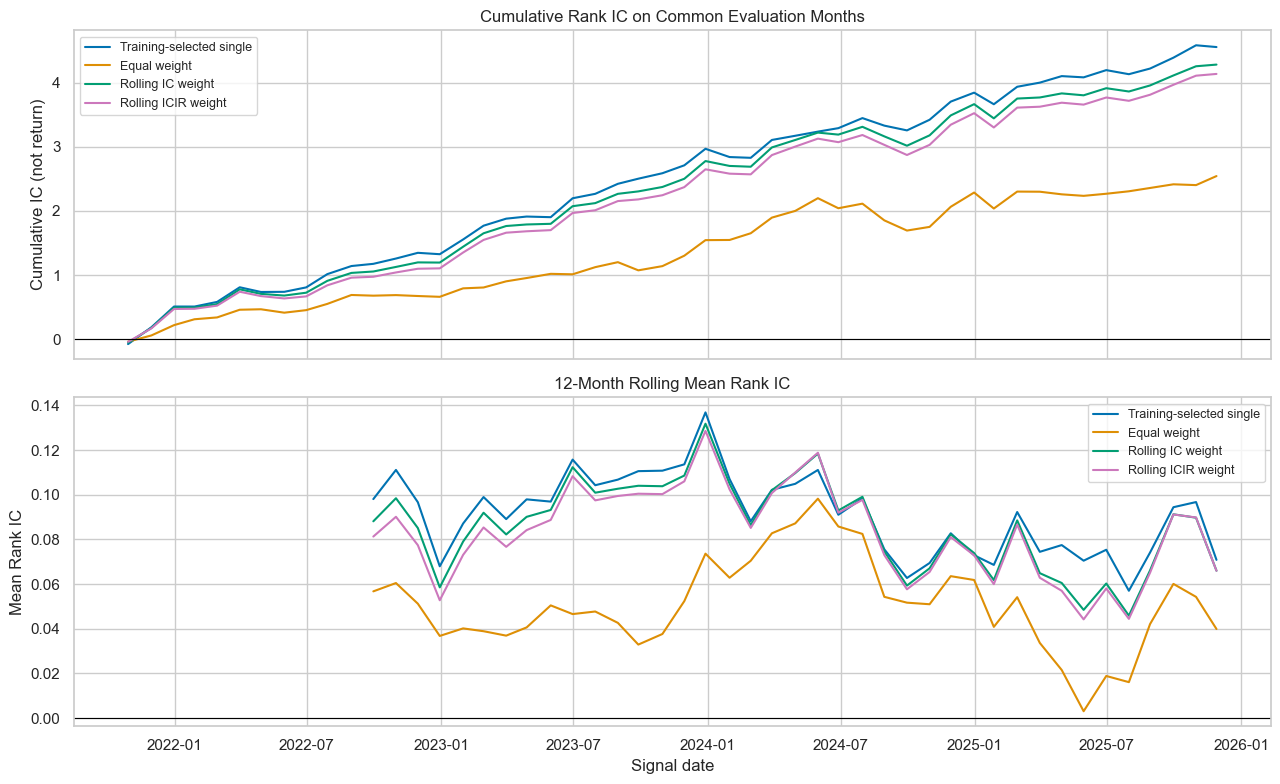

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for score in SCORE_COLUMNS:
    axes[0].plot(evaluation_ic.index, evaluation_ic[score].cumsum(),
                 label=METHOD_LABELS[score], color=COLORS[score])
    axes[1].plot(evaluation_ic.index, evaluation_ic[score].rolling(12).mean(),
                 label=METHOD_LABELS[score], color=COLORS[score])
for ax in axes:
    ax.axhline(0, color='black', linewidth=0.8)
    ax.legend(fontsize=9)
axes[0].set_title('Cumulative Rank IC on Common Evaluation Months')
axes[0].set_ylabel('Cumulative IC (not return)')
axes[1].set_title('12-Month Rolling Mean Rank IC')
axes[1].set_ylabel('Mean Rank IC')
axes[1].set_xlabel('Signal date')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'multifactor_rank_ic.png', dpi=150, bbox_inches='tight')
plt.show()

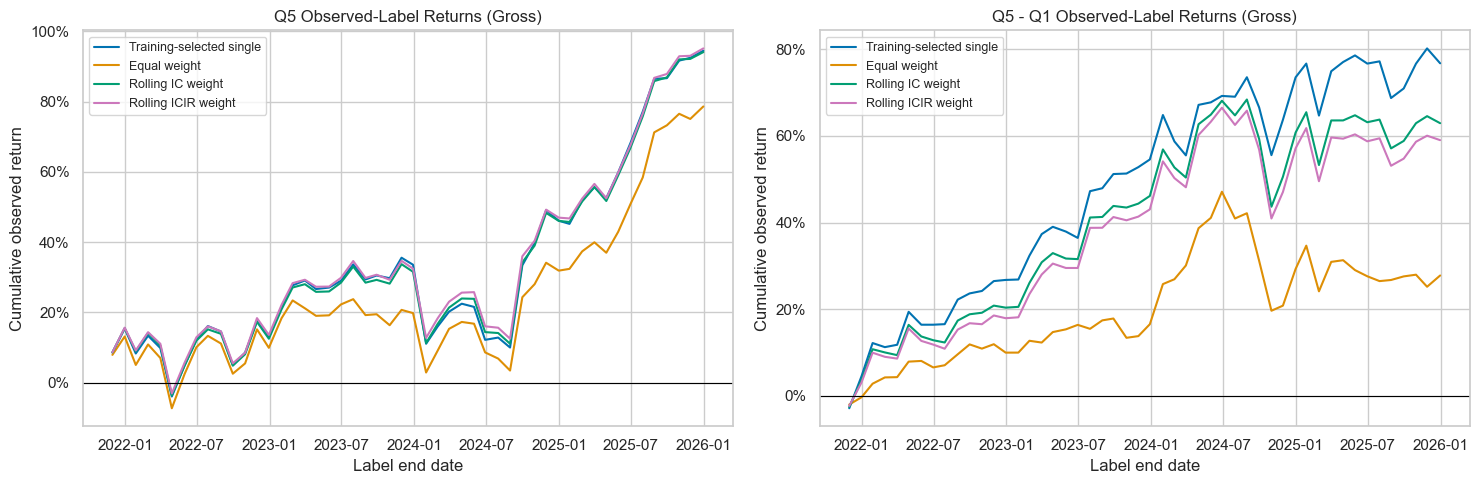

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for score in SCORE_COLUMNS:
    top_curve = calculate_cumulative_returns(top_returns[score])
    ls_curve = calculate_cumulative_returns(long_short_returns[score])
    # 收益归属标签终点，而不是信号形成日，避免曲线提前一个月展示收益。
    axes[0].plot(ic_available_dates.loc[top_curve.index], top_curve,
                 label=METHOD_LABELS[score], color=COLORS[score])
    axes[1].plot(ic_available_dates.loc[ls_curve.index], ls_curve,
                 label=METHOD_LABELS[score], color=COLORS[score])
for ax in axes:
    ax.axhline(0, color='black', linewidth=0.8)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_xlabel('Label end date')
    ax.set_ylabel('Cumulative observed return')
    ax.legend(fontsize=9)
axes[0].set_title('Q5 Observed-Label Returns (Gross)')
axes[1].set_title('Q5 - Q1 Observed-Label Returns (Gross)')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'multifactor_cumulative_returns.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. 分层单调性、目标换手与标签覆盖

除了均值指标，也检查从 Q1 到 Q5 是否有整体单调关系，以及 IC / ICIR 加权是否增加换手。
较低的因子权重变化并不保证股票持仓换手更低，因此直接比较最高组持仓。

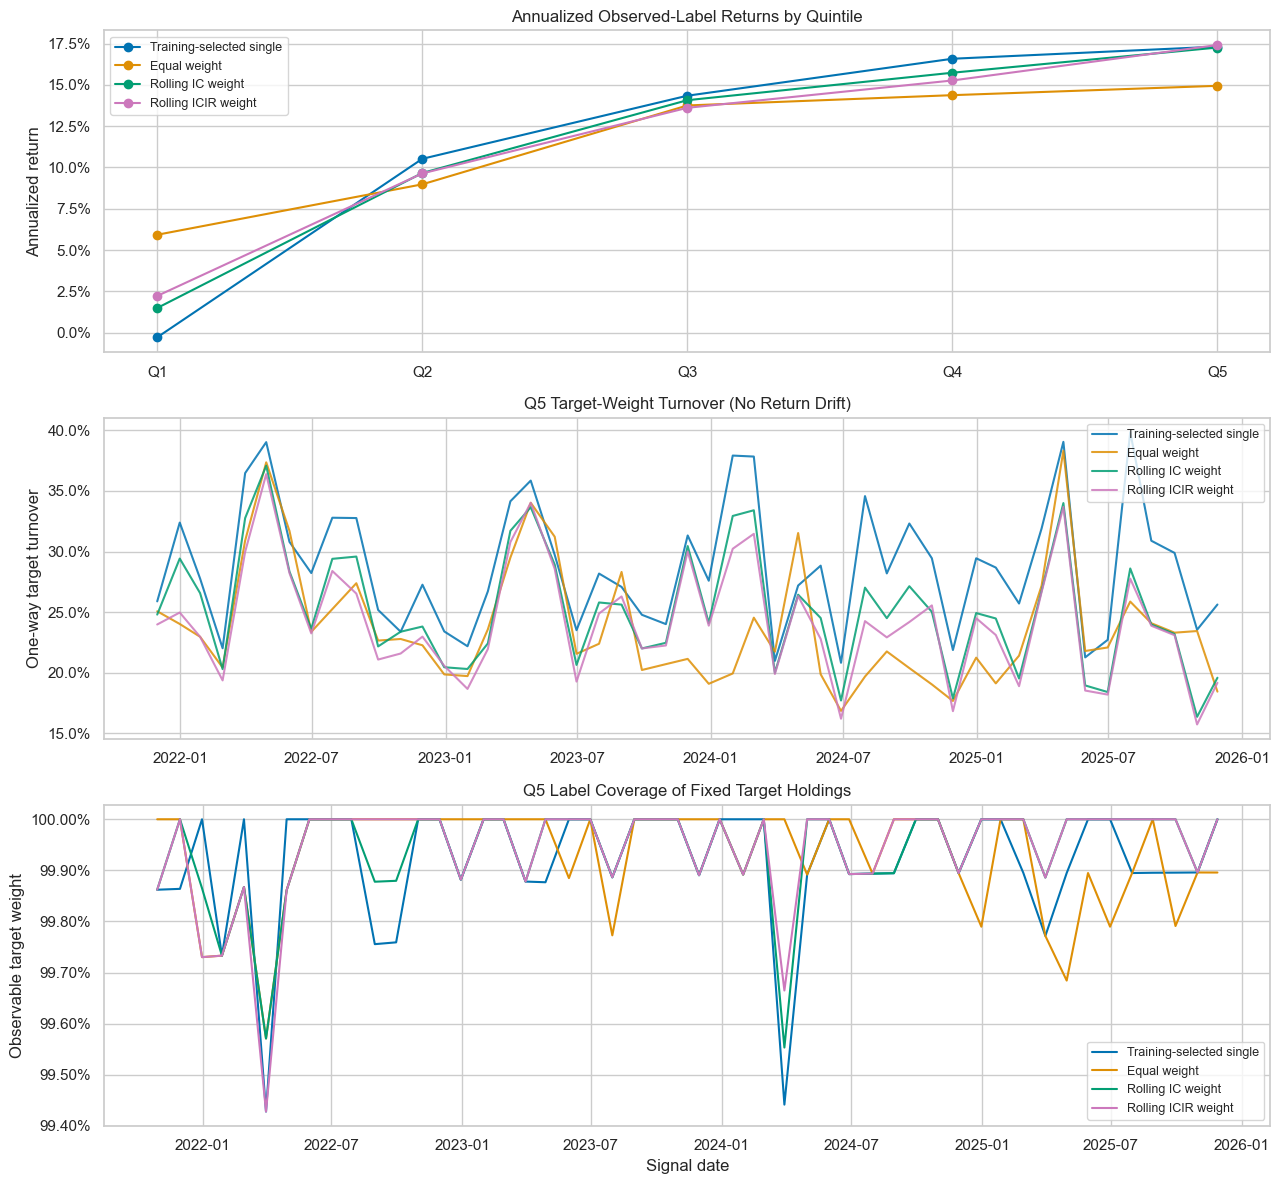

In [10]:
quantile_annualized = pd.DataFrame(index=[f'Q{i}' for i in range(1, N_QUANTILES + 1)])
for score in SCORE_COLUMNS:
    return_panel = build_factor_return_panel(evaluation_quantiles, score, n_quantiles=N_QUANTILES)
    quantile_annualized[score] = [annualized_return(return_panel[q]) for q in quantile_annualized.index]
quantile_annualized.to_csv(PROCESSED_DIR / 'multifactor_quantile_annualized_returns.csv')

fig, axes = plt.subplots(3, 1, figsize=(13, 12))
for score in SCORE_COLUMNS:
    axes[0].plot(quantile_annualized.index, quantile_annualized[score], marker='o',
                 label=METHOD_LABELS[score], color=COLORS[score])
    monthly_turnover = evaluation_turnover.loc[evaluation_turnover.factor.eq(score)]
    axes[1].plot(monthly_turnover.date, monthly_turnover.target_turnover,
                 label=METHOD_LABELS[score], color=COLORS[score], alpha=0.85)
    monthly_coverage = evaluation_quantiles.loc[
        evaluation_quantiles.factor.eq(score) & evaluation_quantiles.quantile_number.eq(N_QUANTILES)
    ]
    axes[2].plot(monthly_coverage.date, monthly_coverage.label_coverage,
                 label=METHOD_LABELS[score], color=COLORS[score])
for ax in axes:
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.legend(fontsize=9)
axes[0].set_title('Annualized Observed-Label Returns by Quintile')
axes[0].set_ylabel('Annualized return')
axes[1].set_title('Q5 Target-Weight Turnover (No Return Drift)')
axes[1].set_ylabel('One-way target turnover')
axes[2].set_title('Q5 Label Coverage of Fixed Target Holdings')
axes[2].set_ylabel('Observable target weight')
axes[2].set_xlabel('Signal date')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'multifactor_quintiles_turnover_coverage.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. 分年份比较与逐期信息检查

固定使用同一组参数，按信号所属年份观察平均 IC、ICIR、最高组收益、多空 Sharpe 和目标换手。
跨年持有期仍归属于信号年份，年初、年末可能不是完整 12 个月，不据此挑选窗口。

下面的信息检查修改比较起点及之后尚未实现的 IC，重新计算权重；
两种滚动方法在起点当日及更早的权重必须完全不变。单元测试还包含延迟可用日、缺失月份、
零 IC、IC 标准差为零、样本标准差手算、负权重、乱序对齐和缺失标签不改变持仓等案例。

In [11]:
yearly_rows = []
for year in sorted(common_dates.year.unique()):
    year_dates = common_dates[common_dates.year == year]
    year_ic = summarize_rank_ic(evaluation_ic.loc[year_dates])
    for score in SCORE_COLUMNS:
        year_ls_metrics = calculate_return_metrics(long_short_returns.loc[year_dates, score])
        yearly_rows.append({
            'Year': year, 'Method': score, 'Months': len(year_dates),
            'Mean Rank IC': year_ic.loc[score, 'Mean Rank IC'],
            'ICIR': year_ic.loc[score, 'ICIR'],
            'Q5 Annualized Return': annualized_return(top_returns.loc[year_dates, score]),
            'LS Sharpe': year_ls_metrics['Sharpe Ratio'],
            'Mean Target Turnover': evaluation_turnover.loc[
                evaluation_turnover.date.isin(year_dates) & evaluation_turnover.factor.eq(score),
                'target_turnover',
            ].mean(),
        })
yearly_comparison = pd.DataFrame(yearly_rows)
yearly_comparison.to_csv(PROCESSED_DIR / 'multifactor_yearly_comparison.csv', index=False)
display(yearly_comparison.pivot(index='Year', columns='Method', values='Mean Rank IC')
        .rename(columns=METHOD_LABELS).style.format('{:.4f}'))

# 只更改尚未实现收益的 IC；两种方法的当前及过去权重都不能变化。
perturbed_ic = monthly_factor_ic.copy()
perturbed_ic.loc[first_ready_date:] = 0.99
for weight_builder, expected in [
    (calculate_rolling_ic_weights, rolling_weights),
    (calculate_rolling_icir_weights, rolling_icir_weights),
]:
    perturbed_weights, _ = weight_builder(
        perturbed_ic, ic_available_dates, signal_dates, window=WINDOW, min_history=MIN_HISTORY,
    )
    pd.testing.assert_frame_equal(
        perturbed_weights.loc[:first_ready_date], expected.loc[:first_ready_date],
    )

# 删除全部未来收益和标签资格，三种合成评分仍应与原来完全相同。
changed_panel = panel.drop(columns=['future_return_1m', 'is_in_label_sample'])
pd.testing.assert_series_equal(
    combine_factor_scores(changed_panel, FACTOR_COLUMNS), panel['equal_weight_score'],
)
for score, (weights, _) in rolling_methods.items():
    pd.testing.assert_series_equal(
        combine_factor_scores(changed_panel, FACTOR_COLUMNS, weights, score_name=score), panel[score],
    )
print('通过：未来 IC 扰动不影响两种滚动权重；三种合成评分均无需读取收益或标签资格。')

Method,Training-selected single,Equal weight,Rolling IC weight,Rolling ICIR weight
Year,,,,
2021,0.1704,0.0739,0.1647,0.1578
2022,0.0679,0.0368,0.0585,0.0527
2023,0.1369,0.0736,0.1318,0.1286
2024,0.0729,0.0618,0.0739,0.0729
2025,0.0646,0.0233,0.0560,0.0556


通过：未来 IC 扰动不影响两种滚动权重；三种合成评分均无需读取收益或标签资格。


## 9. 保存信号、权重、评估与研究结论

`multifactor_scores.parquet` 保留全部股票—日期骨架，可供 Notebook 08 使用；
预热期、因子缺失或不合格记录保留空评分，不删除最后一个无收益标签的信号月。
`multifactor_quantile_holdings.parquet` 保存信号日已确定的分层目标持仓。

本节会自动生成 `reports/07_multifactor_combination.md`，记录本次参数、时间范围、真实指标和限制。
两种滚动权重与窗口审计、月度 IC、分组标签覆盖率、目标换手、逐年结果统一写入 `data/processed/`，
图写入 `figures/multifactor_*.png`。

In [12]:
score_output_columns = [*context_columns, 'label_end_date', 'has_complete_factors',
                        *FACTOR_COLUMNS, *SCORE_COLUMNS]
panel[score_output_columns].to_parquet(PROCESSED_DIR / 'multifactor_scores.parquet', index=False)
holdings.to_parquet(PROCESSED_DIR / 'multifactor_quantile_holdings.parquet', index=False)
quantile_returns.to_parquet(PROCESSED_DIR / 'multifactor_quantile_returns.parquet', index=False)
monthly_score_ic.to_parquet(PROCESSED_DIR / 'multifactor_score_rank_ic_monthly.parquet')
turnover.to_parquet(PROCESSED_DIR / 'multifactor_target_turnover.parquet', index=False)
long_short_returns.to_parquet(PROCESSED_DIR / 'multifactor_long_short_returns.parquet')
top_returns.to_parquet(PROCESSED_DIR / 'multifactor_top_quantile_returns.parquet')

# 自动结论只陈述实测差异，不因一个汇总指标占优就声称策略可交易或统计显著。
ew = comparison.loc['equal_weight_score']
icw = comparison.loc['ic_weight_score']
icirw = comparison.loc['icir_weight_score']
conclusion_lines = []
for score, label in [('ic_weight_score', '滚动 IC 加权'), ('icir_weight_score', '滚动 ICIR 加权')]:
    result = comparison.loc[score]
    conclusion_lines.append(
        f"{label}相对等权：ICIR 变化 {result['ICIR'] - ew['ICIR']:+.3f}，"
        f"Q5−Q1 Sharpe 变化 {result['LS Sharpe'] - ew['LS Sharpe']:+.2f}，"
        f"平均月度目标换手变化 {(result['Mean Target Turnover'] - ew['Mean Target Turnover']) * 100:+.2f} 个百分点。"
    )
conclusion_lines.append(
    f"滚动 ICIR 加权相对 IC 加权：ICIR 变化 {icirw['ICIR'] - icw['ICIR']:+.3f}，"
    f"Q5−Q1 Sharpe 变化 {icirw['LS Sharpe'] - icw['LS Sharpe']:+.2f}，"
    f"平均月度目标换手变化 {(icirw['Mean Target Turnover'] - icw['Mean Target Turnover']) * 100:+.2f} 个百分点。"
)
report_table = comparison.rename(index=METHOD_LABELS).round(4).to_string()
report_lines = [
    '# Notebook 07：多因子合成运行记录', '',
    '## 固定设定', '',
    '- 输入：factor_panel_industry_size_neutral.parquet（行业、市值联合中性化并标准化）。',
    '- 因子：EP、ROE、12-1 动量、60 日低波动；每类一个因子。',
    f'- 方法：四因子等权；{WINDOW} 个月滚动平均 Rank IC 加权；同窗口滚动 ICIR 加权。',
    '- ICIR 使用历史 IC 均值 / 样本标准差（ddof=1），不年化；两种滚动方法只使用当期已实现收益。',
    '- 任一因子的 IC 标准差为零或无法估计，整组 ICIR 权重留空，不回退、不删除因子；真实很小的正标准差不截断。',
    f'- 每因子最少 {MIN_HISTORY} 个有效历史 IC，允许负权重，绝对权重之和为 1；历史不足留空。',
    f'- 输入信号日：{signal_dates.min():%Y-%m-%d} 至 {signal_dates.max():%Y-%m-%d}，{len(signal_dates)} 个月。',
    f'- 首个可用滚动 IC 权重日：{first_ready_date:%Y-%m-%d}；滚动 ICIR 权重日：{first_icir_ready_date:%Y-%m-%d}。',
    f'- 初始选择窗口：{training_ic.index.min():%Y-%m-%d} 至 {training_ic.index.max():%Y-%m-%d}。',
    f'- 固定单因子基准：{FACTOR_LABELS[best_factor]}，按初始历史平均 IC 选择。',
    f'- 共同评价信号日：{common_dates.min():%Y-%m-%d} 至 {common_dates.max():%Y-%m-%d}，{len(common_dates)} 个月。',
    f'- 最后信号月 {signal_dates[-1]:%Y-%m-%d} 保留信号，不评价尚未实现的收益。',
    '', '## 真实结果', '', '百分比字段以小数表示；ICIR 不年化；Sharpe 按月度收益年化。',
    '', '```text', report_table, '```', '', *conclusion_lines, '',
    '## 解释边界', '',
    '- 分组先于连接标签；缺失标签不改变持仓。组收益在有效标签持仓内重新归一化，属于可观察标签条件收益。',
    '- 结果表同时报告 Q5 平均与最低标签权重覆盖率，完整覆盖明细见 multifactor_quantile_returns.parquet。',
    '- 目标换手不含价格漂移；首次建仓不计入换手均值；Q5−Q1 是未计成本及做空限制的研究型收益。',
    '- 延续 close-to-close 标签定义；尚未按下一交易日开盘价模拟真实交易。',
    '- 因子中性化不保证分组后的组合行业、市值严格中性。',
    '- 当前为初始历史选基准、向前滚动估计的研究比较，未隔离最终测试集；前序 notebook 已展示全样本结果。',
    '- 不据本次结果调整因子、窗口或方向；Notebook 08/09/10 继续处理组合、成本、约束与严格样本外评估。',
    '', '## 复现', '',
    '从项目根目录的 Python 环境运行 notebooks/07_multifactor_combination.ipynb。',
    '输入依赖 Notebook 06 生成的联合中性化面板。单元测试：python -m pytest tests/test_multifactor.py -q。',
]
report_path = REPORTS_DIR / '07_multifactor_combination.md'
report_path.write_text('\n'.join(report_lines) + '\n', encoding='utf-8')
display(Markdown('\n\n'.join(conclusion_lines)))
print(f'信号、持仓及评估已保存至：{PROCESSED_DIR}')
print(f'研究记录：{report_path}')

滚动 IC 加权相对等权：ICIR 变化 +0.245，Q5−Q1 Sharpe 变化 +0.40，平均月度目标换手变化 +1.40 个百分点。

滚动 ICIR 加权相对等权：ICIR 变化 +0.226，Q5−Q1 Sharpe 变化 +0.35，平均月度目标换手变化 +0.41 个百分点。

滚动 ICIR 加权相对 IC 加权：ICIR 变化 -0.019，Q5−Q1 Sharpe 变化 -0.05，平均月度目标换手变化 -0.99 个百分点。

信号、持仓及评估已保存至：/Users/mac/Desktop/a-share-multifactor/data/processed
研究记录：/Users/mac/Desktop/a-share-multifactor/reports/07_multifactor_combination.md
